# PathSnap: Phase 1, preprocessing and feature engineering
Each step runs on the raw data using the same library code as the full pipeline (`src/pathsnap/`).
**Partitions:** the live demos use TRAIN trips. The partition-level tables come from `scripts/02_eda.py` (TRAIN + STUDENT_TEST).
The evaluator-test data is never used.

In [27]:
import os, sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('../src'))
from pathsnap.io import load_trip, list_trips
from pathsnap.geo import clean_track, LocalProjection, Network, heading_from_track
from pathsnap.labels import align_route
from pathsnap.features import prepare_trip, filter_candidates, FEATURES, FINAL_CFG
DATA = os.environ.get('PATHSNAP_DATA', '../data')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
print('train trips:', len(list_trips(f'{DATA}/train')), '| student_test trips:', len(list_trips(f'{DATA}/student_test')))

train trips: 80 | student_test trips: 10


## 1. Raw files of one trip
Each file has no header. The row index is the id: node id for `.nodes`, arc id for `.arcs`.

In [28]:
TID = '00000011'   # a trip with a loop and twin arcs, which is where labelling is hard
trip = load_trip(f'{DATA}/train', TID)
for name, arr in [('track (lon, lat, t)', trip.track), ('nodes (lon, lat)', trip.nodes),
                  ('arcs (from_node, to_node)', trip.arcs), ('route (arc_id, in order)', trip.route)]:
    print(f'{name:28s} shape={arr.shape}  first rows: {np.asarray(arr)[:3].tolist()}')

track (lon, lat, t)          shape=(2828, 3)  first rows: [[60.015437, 56.067531, 1.0], [60.015259, 56.067503, 2.0], [60.015045, 56.06749, 3.0]]
nodes (lon, lat)             shape=(2649, 2)  first rows: [[60.022182, 56.065212], [60.013052, 56.067294], [60.003781, 56.065898]]
arcs (from_node, to_node)    shape=(5393, 2)  first rows: [[0, 60], [0, 57], [0, 196]]
route (arc_id, in order)     shape=(565,)  first rows: [417, 862, 129]


## 2. Dataset inventory and data quality (TRAIN vs STUDENT_TEST)

In [29]:
inv = pd.read_csv('../results/eda/inventory.csv', dtype={'trip': str})
summ = inv.groupby('split').agg(trips=('trip','count'), gps_obs=('n_obs','sum'), obs_median=('n_obs','median'),
        missing_values=('n_nan','sum'), non_monotonic_t=('non_monotonic','sum'), gaps_over_5s=('n_gaps_gt5s','sum'),
        frac_1s_steps=('dt_1s_frac','mean'), median_arcs=('n_arcs','median'), isolated_nodes=('isolated_nodes','sum'),
        median_weak_components=('weak_components','median'), routes_contiguous=('route_contiguous','mean'),
        twin_arc_frac=('twin_arc_frac','mean'))
summ.T.round(3)

split,student_test,train
trips,10.000,80.000
gps_obs,19160.000,208417.000
obs_median,1420.000,1529.000
missing_values,0.000,0.000
non_monotonic_t,0.000,0.000
gaps_over_5s,44.000,1216.000
frac_1s_steps,0.982,0.938
median_arcs,13145.000,19526.500
isolated_nodes,0.000,0.000
median_weak_components,11.000,20.000


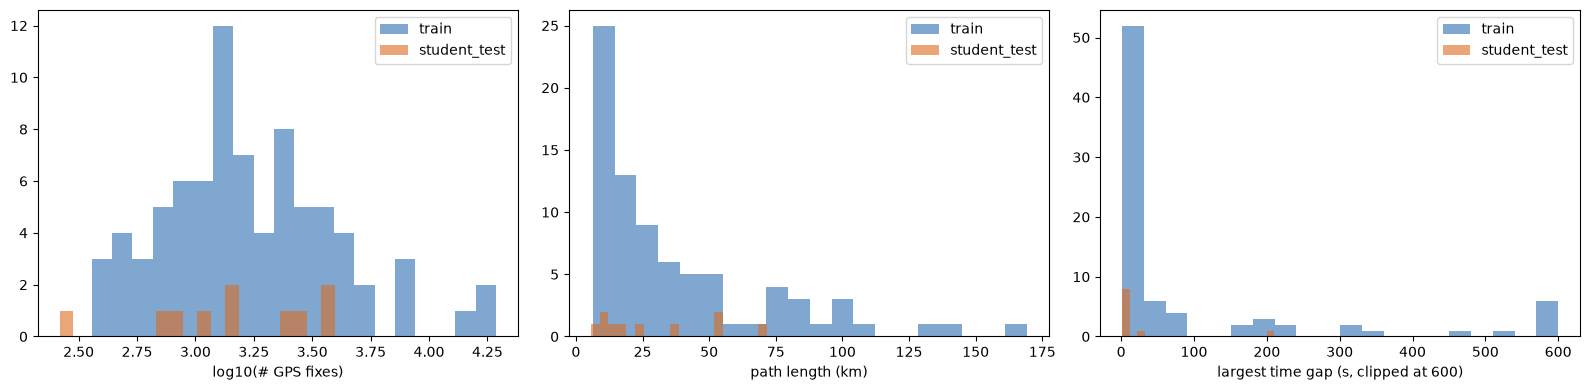

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for s, c in [('train', '#2b6cb0'), ('student_test', '#dd6b20')]:
    d = inv[inv.split == s]
    ax[0].hist(np.log10(d.n_obs), bins=20, alpha=.6, color=c, label=s)
    ax[1].hist(d.path_len_km, bins=20, alpha=.6, color=c, label=s)
    ax[2].hist(d.dt_max.clip(upper=600), bins=20, alpha=.6, color=c, label=s)
ax[0].set_xlabel('log10(# GPS fixes)'); ax[1].set_xlabel('path length (km)'); ax[2].set_xlabel('largest time gap (s, clipped at 600)')
for a in ax: a.legend()
plt.tight_layout()

**What we see:** there are no missing values, and timestamps are always in order. The data is nominally 1 Hz, but there are 1,216 gaps over 5 s in TRAIN.
The networks are fragmented into many components, and 11 of the 90 reference routes are not contiguous. Trips are spread worldwide, so each trip needs its own projection.

## 3. Cleaning and projection
We drop invalid, out-of-order and duplicate-time fixes, then project to metres with a local equirectangular projection centred on the trip.

In [31]:
track, rep = clean_track(trip.track)
print('cleaning report:', rep)
proj = LocalProjection(np.median(track[:,0]), np.median(track[:,1]))
xy = proj.fwd(track[:,0], track[:,1])
deg = np.hypot(*np.diff(track[:,:2], axis=0).T)        # naive degree distance (wrong)
m = np.hypot(*np.diff(xy, axis=0).T)                    # metres
print(f'median step: {np.median(deg):.6f} degrees  vs  {np.median(m):.1f} m  (~{np.median(m)*3.6:.0f} km/h at 1 Hz)')
lat0 = np.radians(proj.lat0); print(f'1 deg lon = {proj.kx/1000:.1f} km but 1 deg lat = {proj.ky/1000:.1f} km here, which is why degrees cannot be used as distance')

cleaning report: {'n_raw': 2828, 'n_invalid': 0, 'n_out_of_order': 0, 'n_dup_time': 0, 'n_clean': 2828}
median step: 0.000275 degrees  vs  19.0 m  (~68 km/h at 1 Hz)
1 deg lon = 62.1 km but 1 deg lat = 111.2 km here, which is why degrees cannot be used as distance


## 4. Network cropping

In [32]:
net = Network(trip.nodes, trip.arcs, proj, (xy.min(0), xy.max(0)), buffer_m=800)
print(f'arcs in file: {len(trip.arcs):,} -> kept after crop (GPS bbox + 800 m): {len(net.arc_ids):,}')
print(f'route arcs inside crop: {np.isin(trip.route, net.arc_ids).mean():.0%}')

arcs in file: 5,393 -> kept after crop (GPS bbox + 800 m): 5,055
route arcs inside crop: 100%


## 5. Per-fix labels from the route (monotonic DP alignment)
`.route` gives the arcs in order but does not say which fix is on which arc. The DP minimises total fix-to-arc distance and never lets the route position go backwards in time.
Below, we compare it with naive "snap each fix to the nearest route arc".

In [33]:
pos, lab, ldist = align_route(xy, net.nodes_xy, trip.arcs, trip.route)
# naive: nearest route arc, ignoring order
from pathsnap.labels import _route_dists
D = _route_dists(xy, net.nodes_xy, trip.arcs, trip.route)
naive = trip.route[D.argmin(1)]
print(f'fixes: {len(xy)} | DP label distance median {np.median(ldist):.1f} m, p95 {np.percentile(ldist,95):.1f} m')
print(f'naive nearest-arc labels disagree with DP on {np.mean(naive != lab):.1%} of fixes')
twin = [(trip.arcs[a,0]==trip.arcs[b,1]) and (trip.arcs[a,1]==trip.arcs[b,0]) for a,b in zip(naive, lab)]
if (naive != lab).any(): print(f'  of those disagreements, {np.mean(np.array(twin)[naive != lab]):.0%} are the reverse-direction twin arc')
print('route position never decreases:', bool(np.all(np.diff(pos) >= 0)))

fixes: 2828 | DP label distance median 5.1 m, p95 14.5 m
naive nearest-arc labels disagree with DP on 43.3% of fixes
  of those disagreements, 100% are the reverse-direction twin arc
route position never decreases: True


In [34]:
rep = pd.read_csv('../results/eda/preprocess_report.csv', dtype={'trip': str})
print(json.load(open('../results/eda/excluded_trips.json')))
rep[rep.split=='train'].sort_values('label_dist_median', ascending=False)[['trip','n_clean','label_dist_median','label_dist_p95']].head(5)

{'rule': 'train trips with median(fix -> reference arc distance) > 50 m', 'excluded': ['00000033', '00000054']}


,trip,n_clean,label_dist_median,label_dist_p95
44,00000054,19313,140.008820,209.620773
26,00000033,5844,122.383224,142.022522
35,00000043,2322,10.997238,70.024376
3,00000004,1064,8.506742,29.475609
6,00000008,3093,7.787961,28.161886


Trips 33 and 54 sit 120–140 m away from their own reference route, so their labels are unreliable. Both are **excluded from training**; 78 train trips remain.

## 6. Candidate generation: choosing the radius and K on TRAIN

In [35]:
grid = pd.read_csv('../results/eda/candidate_radius_grid_train.csv')
g = grid.pivot(index='radius', columns='k', values='miss_rate').mul(100).round(2)
g.columns = [f'K={k}' for k in g.columns]; g.index.name = 'radius (m)'
print('candidate miss rate (%) on TRAIN:'); display(g)
r = grid.set_index(['radius','k']).rows
print(f"chosen 50 m / K=8: {r[(50,8)]:,} rows;  80 m / K=12 would need {r[(80,12)]:,} rows (+{r[(80,12)]/r[(50,8)]-1:.0%}) for <1 pt gain")

candidate miss rate (%) on TRAIN:


,K=4,K=6,K=8,K=10,K=12
radius (m),,,,,
20,6.32,5.11,4.79,4.68,4.62
30,4.63,3.23,2.80,2.65,2.57
40,3.99,2.55,2.07,1.89,1.81
50,3.80,2.34,1.85,1.66,1.57
60,3.67,2.20,1.69,1.50,1.41
80,3.29,1.80,1.29,1.08,0.99


chosen 50 m / K=8: 1,033,008 rows;  80 m / K=12 would need 1,569,488 rows (+52%) for <1 pt gain


## 7. Feature engineering: 21 features per (fix, candidate arc)

In [36]:
P = prepare_trip(trip, {'radius': 80, 'k_max': 12})          # wide pass, same as the training pipeline
df = filter_candidates(P.df, FINAL_CFG['radius'], FINAL_CFG['k_max'])
print(f'{P.n_obs} fixes -> {len(df)} candidate rows ({len(df)/P.n_obs:.1f} per fix), positives {df.y.mean():.1%}')
print(f"fixes whose true arc is in the candidate set: {df[df.y==1].obs.nunique()/P.n_obs:.2%}")
df[df.obs == 200][['arc','y'] + FEATURES].round(2)

2828 fixes -> 13216 candidate rows (4.7 per fix), positives 21.4%
fixes whose true arc is in the candidate set: 99.96%


,arc,y,dist,dist_rank,dist_minus_min,dist_softmax,head_diff,head_diff_long,head_diff_undirected,speed,step_len,dt,arc_len,proj_frac,proj_overshoot,n_cands,win_dist_mean,win_dist_max,dist_prev,dist_next,out_deg_to,in_deg_from,has_twin
1040,711,0,6.76,0,0.00,0.49,167.86,172.79,12.14,14.58,16.35,1.0,133.4,0.21,0.00,4,10.72,14.89,8.57,14.70,2,2,1
1041,714,1,6.76,1,0.00,0.49,12.14,7.21,12.14,14.58,16.35,1.0,133.4,0.79,0.00,4,10.72,14.89,8.57,14.70,2,2,1
1042,709,0,29.29,2,22.52,0.01,173.23,167.43,6.77,14.58,16.35,1.0,58.2,1.00,0.48,4,31.55,61.08,45.56,21.91,2,2,1
1043,712,0,29.29,3,22.52,0.01,6.77,12.57,6.77,14.58,16.35,1.0,58.2,0.00,0.48,4,31.55,61.08,45.56,21.91,2,2,1


In [37]:
groups = {
 'Geometry': ['dist','dist_rank','dist_minus_min','dist_softmax'],
 'Direction (separates reverse twins)': ['head_diff','head_diff_long','head_diff_undirected'],
 'Kinematics / gaps': ['speed','step_len','dt'],
 'Temporal context (t-3..t+3)': ['win_dist_mean','win_dist_max','dist_prev','dist_next'],
 'Arc & topology': ['arc_len','proj_frac','proj_overshoot','out_deg_to','in_deg_from','has_twin','n_cands']}
pd.DataFrame([(g, f) for g, fs in groups.items() for f in fs], columns=['group','feature']).groupby('group').feature.apply(', '.join).to_frame()

,feature
group,
Arc & topology,"arc_len, proj_frac, proj_overshoot, out_deg_to..."
Direction (separates reverse twins),"head_diff, head_diff_long, head_diff_undirected"
Geometry,"dist, dist_rank, dist_minus_min, dist_softmax"
Kinematics / gaps,"speed, step_len, dt"
Temporal context (t-3..t+3),"win_dist_mean, win_dist_max, dist_prev, dist_next"


### Do the features separate correct from wrong candidates? (8 TRAIN trips, live)

122,574 candidate rows from 8 train trips


,dist,dist_minus_min,head_diff,head_diff_long,win_dist_mean,proj_overshoot
y,,,,,,
"median, wrong arc",17.31,10.14,96.27,99.34,20.18,0.15
"median, correct arc",5.22,0.00,31.70,10.88,6.52,0.00


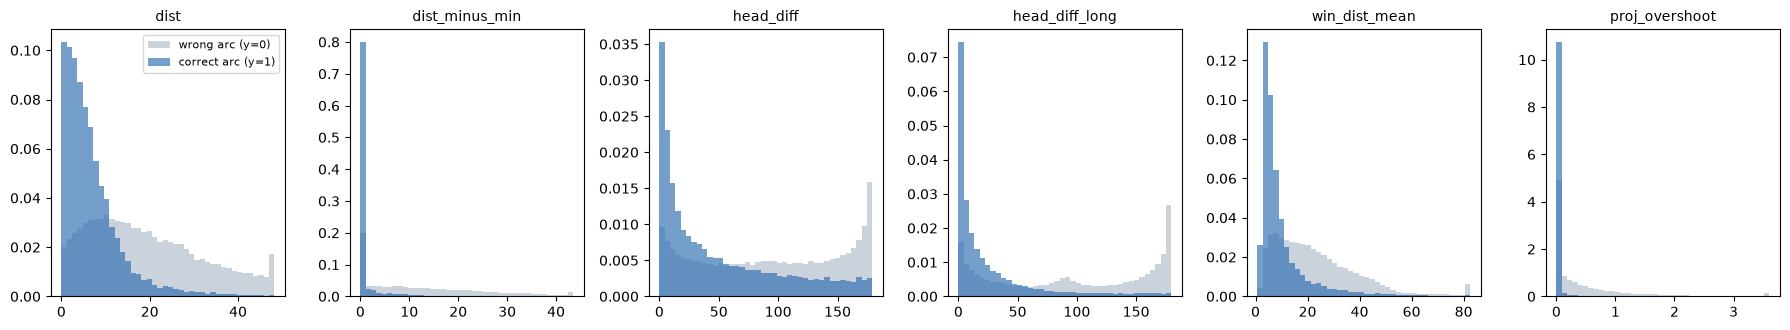

In [38]:
tids = list_trips(f'{DATA}/train')[:10]
tids = [t for t in tids if t not in ('00000033','00000054')][:8]
F = pd.concat([filter_candidates(prepare_trip(load_trip(f'{DATA}/train', t), {'radius':80,'k_max':12}).df, 50, 8) for t in tids])
show = ['dist','dist_minus_min','head_diff','head_diff_long','win_dist_mean','proj_overshoot']
fig, axs = plt.subplots(1, len(show), figsize=(18, 3.4))
for a, f in zip(axs, show):
    v0, v1 = F.loc[F.y==0, f], F.loc[F.y==1, f]
    hi = np.percentile(F[f], 99)
    a.hist(v0.clip(upper=hi), bins=40, alpha=.55, density=True, label='wrong arc (y=0)', color='#a0aec0')
    a.hist(v1.clip(upper=hi), bins=40, alpha=.65, density=True, label='correct arc (y=1)', color='#2b6cb0')
    a.set_title(f, fontsize=10)
axs[0].legend(fontsize=8); plt.tight_layout()
print(f'{len(F):,} candidate rows from {len(tids)} train trips')
F.groupby('y')[show].median().round(2).rename(index={0:'median, wrong arc',1:'median, correct arc'})

**Reading the plots:** correct arcs are closer (`dist`, `win_dist_mean`) and point the same way the car is moving (`head_diff` ≈ 0°, while the reverse twin sits ≈ 180°).
They also rarely project past the end of the arc (`proj_overshoot`). Heading is the only feature that can separate an arc from its reverse twin: 92 % of arcs have one, and the twin has identical geometry.

## 8. Folium map: raw GPS, road network and reference route (TRAIN trip)

In [39]:
from pathsnap.viz import trip_map
m = trip_map(P, reference_route=trip.route, title=f'train {TID}: raw GPS, network, reference route')
m

## Summary of Phase 1
| step | decision | evidence |
|---|---|---|
| cleaning | drop invalid / out-of-order / duplicate-time fixes; keep gaps | 0 missing, 1,216 gaps > 5 s (TRAIN) |
| projection | per-trip local equirectangular, metres | trips span latitude -34° to 62° |
| cropping | GPS bbox + 800 m | 100 % of route arcs kept; speeds up search and Dijkstra |
| labels | monotonic DP alignment to `.route` | naive snapping disagrees on 43 % of trip 11's fixes |
| anomalies | exclude train trips 33, 54 | median offset 122 m / 140 m |
| candidates | radius 50 m, K = 8 | 1.85 % miss on TRAIN, 0.42 % on student-test |
| features | 21 (geometry, heading, kinematics, context, topology) | clear class separation in Section 7 |